# Composers and the history of music in the latent space

*Question 4 of the latent-space analysis.*

The model learned to compress single bars of music, from Corelli in the 1680s to Medtner in the
1920s, without ever being told who wrote them or when. Did it nevertheless pick up what makes
a composer's music recognisable, or how piano music changed over 150 years?

We ask four questions:

1. **Who wrote this bar?** Can the composer be recognised from a single bar's code, and from all
   the bars of a piece?
2. **Who sounds like whom?** When the code is unsure, which composers does it mix up?
3. **When was it written?** Can the code date a piece?
4. **What does "later" sound like?** If we push a bar from the 1780s towards "later" in the code,
   what changes in the music?

To keep the answers honest:

- **every bar is transposed to C** before encoding, so that a composer's favourite keys can't
  give them away (pieces without an annotated key are left out);
- **every piece is judged by a probe that never saw it**: the pieces are split into five groups,
  and the probe for each group is trained on the other four. Unlike the earlier notebooks, this
  tests every piece of the corpus, not only the 60 validation pieces;
- composers are **weighted equally** when training the probes, so that composers with many
  pieces (Beethoven: 131) don't drown out those with few (Debussy: 3);
- we compare the **compact** and **detailed** models with the **untrained** control, with the
  **simple features** of the first notebook (register, density, dissonance, note names...), and
  with the compact model's code and the simple features **combined**.

The sound examples are saved as WAV and MIDI files in `outputs/q4`, with a link below each
example. Running this notebook takes about 30 minutes on a laptop CPU.

In [1]:
import os
from pathlib import Path

root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)  # paths below are relative to the repository root

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.exceptions import ConvergenceWarning

from pianotree_dcml.analysis.audio import save_wav, synthesize, to_midi
from pianotree_dcml.analysis.decode import decode
from pianotree_dcml.analysis.directions import mean_difference_direction, move_and_measure, spread_along
from pianotree_dcml.analysis.encode import dataset_for, load_embeddings
from pianotree_dcml.analysis.features import FEATURES, bar_features
from pianotree_dcml.analysis.plots import plot_bars
from pianotree_dcml.analysis.probes import cross_validated_predictions, score_predictions
from pianotree_dcml.analysis.similarity import mantel
from pianotree_dcml.train import load_checkpoint

warnings.filterwarnings("ignore", category=ConvergenceWarning)

OUT = Path("notebooks/outputs/q4")  # figures and sounds, e.g. for a blog post
OUT.mkdir(parents=True, exist_ok=True)

def listen(path):
    # A link to a sound file; audio players are kept out of the notebook to keep it small.
    display(Markdown(f"Listen: [{path.name}]({path.relative_to('notebooks').as_posix()})"))

codes = {"compact (β = 0.1)": load_embeddings("runs/full/embeddings_to_c.npz"),
         "detailed (β = 0.01)": load_embeddings("runs/full_beta0.01/embeddings_to_c.npz"),
         "untrained": load_embeddings("runs/full/embeddings_to_c_untrained.npz")}
bars = codes["compact (β = 0.1)"].bars
dataset = dataset_for(codes["compact (β = 0.1)"])
features = bar_features(dataset.notes_table(), bars.bar_len)

def standardise(x):
    return (x - x.mean(axis=0)) / (x.std(axis=0) + 1e-9)

simple = features.fillna(features.median()).to_numpy()
representations = {name: e.mean for name, e in codes.items()}
representations["simple features"] = simple
representations["compact + simple features"] = np.hstack(
    [standardise(codes["compact (β = 0.1)"].mean), standardise(simple)])
COLORS = {"compact (β = 0.1)": "tab:blue", "detailed (β = 0.01)": "tab:orange",
          "untrained": "tab:gray", "simple features": "tab:green",
          "compact + simple features": "tab:purple"}

pieces = (bars.corpus + "/" + bars.piece).to_numpy()
composer = bars.composer.str.split().str[-1].to_numpy()
year = bars.year.to_numpy().astype(float)
piano = ~bars.corpus.isin(["ABC", "corelli"]).to_numpy()  # solo piano music only
print(f"{len(bars)} bars from {len(set(pieces))} pieces")
display(pd.DataFrame({"pieces": pd.Series(pieces).groupby(composer).nunique(),
                      "bars": pd.Series(composer).value_counts(),
                      "year (median)": pd.Series(year).groupby(composer).median().astype(int)})
        .sort_values("year (median)"))

55970 bars from 508 pieces


,pieces,bars,year (median)
Corelli,126,4113,1689
Mozart,54,7508,1783
Beethoven,131,26782,1804
Chopin,55,4909,1838
Schumann,13,400,1839
Liszt,18,2279,1858
Tchaikovsky,12,1210,1876
Dvořák,12,676,1879
Grieg,65,5274,1893
Debussy,3,349,1905


## 1. Who wrote this bar?

For each kind of code, a probe learns to recognise the composer from the code of a bar. We
score it in two ways: from **one bar** at a time, and for **whole pieces**, by averaging the
probe's guesses over all the bars of a piece. The score is the share of each composer's bars (or
pieces) recognised, averaged over composers, so that guessing at random gets 1 in 11 (9%) for
all composers and 1 in 10 for solo piano.

The corpus mixes instruments: Corelli wrote for two violins and continuo, Beethoven's quartets
for strings, everything else is solo piano. Recognising Corelli may simply mean recognising a
trio sonata. So we also ask the question within **solo piano only**, where ten composers write
for the same instrument.

codes                      compact (β = 0.1)  detailed (β = 0.01)  untrained  \
task          level                                                            
all composers one bar                   0.32                 0.33       0.27   
              whole piece               0.51                 0.48       0.42   
solo piano    one bar                   0.27                 0.28       0.24   
              whole piece               0.43                 0.43       0.36   

codes                      simple features  compact + simple features  
task          level                                                    
all composers one bar                 0.29                       0.33  
              whole piece             0.42                       0.53  
solo piano    one bar                 0.26                       0.29  
              whole piece             0.34                       0.45

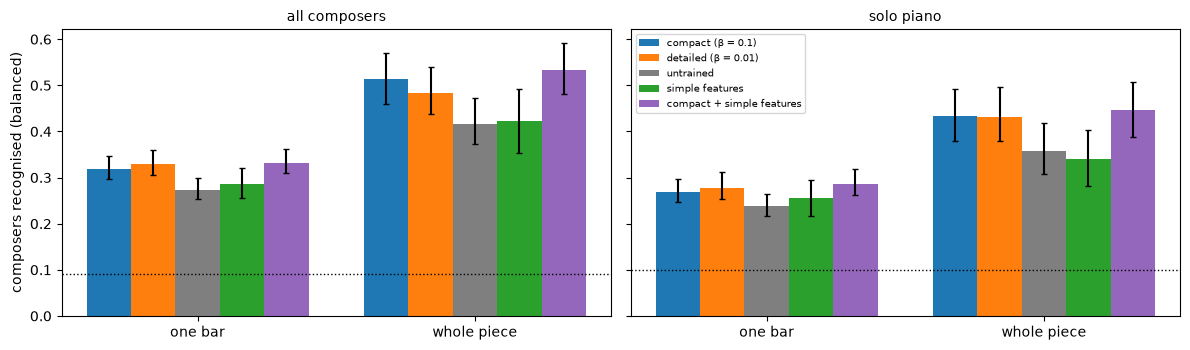

In [2]:
def composer_probe(mask, x):
    classes = np.unique(composer[mask])
    probabilities = cross_validated_predictions(x[mask], composer[mask], pieces[mask],
                                                "category", balanced=True)
    by_bar = score_predictions(composer[mask], classes[probabilities.argmax(axis=1)],
                               pieces[mask], "category")
    by_piece = (pd.DataFrame(probabilities, columns=classes)
                .assign(piece=pieces[mask], composer=composer[mask])
                .groupby("piece").agg({**{c: "mean" for c in classes}, "composer": "first"}))
    piece_score = score_predictions(by_piece.composer.to_numpy(),
                                    classes[by_piece[classes].to_numpy().argmax(axis=1)],
                                    by_piece.index.to_numpy(), "category")
    return by_bar, piece_score, by_piece

rows, piano_pieces = [], {}
for task, mask in [("all composers", np.ones(len(bars), bool)), ("solo piano", piano)]:
    for name, x in representations.items():
        by_bar, by_piece, probabilities = composer_probe(mask, x)
        if task == "solo piano":
            piano_pieces[name] = probabilities
        for level, result in [("one bar", by_bar), ("whole piece", by_piece)]:
            rows.append({"task": task, "codes": name, "level": level, "score": result.score,
                         "low": result.low, "high": result.high, "chance": result.chance})
composer_results = pd.DataFrame(rows)
display(composer_results.pivot_table(index=["task", "level"], columns="codes", values="score",
                                     sort=False)[list(representations)].round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, task in zip(axes, ["all composers", "solo piano"]):
    part = composer_results[composer_results.task == task]
    for j, name in enumerate(representations):
        rows_ = part[part.codes == name].set_index("level").loc[["one bar", "whole piece"]]
        positions = np.arange(2) + (j - 2) * 0.16
        ax.bar(positions, rows_.score, 0.16, color=COLORS[name], label=name,
               yerr=np.abs(rows_[["low", "high"]].to_numpy().T - rows_.score.to_numpy()), capsize=2)
    ax.axhline(part.chance.iloc[0], color="k", linestyle=":", linewidth=1)
    ax.set_xticks(range(2), ["one bar", "whole piece"])
    ax.set_title(task, fontsize=10)
axes[0].set_ylabel("composers recognised (balanced)")
axes[1].legend(fontsize=7, loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "which_composer.png", dpi=150)

From a single bar, the compact model's code recognises the composer about a third of the time
(32%), three and a half times better than chance (9%). Judging a whole piece by all its bars, it
gets about half of them right (51%).

That sounds impressive, but the controls put it in perspective. The simple features (register,
density, note lengths, dissonance...) already recognise 29% of bars, and the untrained model 27%:
much of a composer's fingerprint is visible in plain surface statistics. The trained code adds a
few points for single bars, and about ten for whole pieces (51% against 42% for both controls).
Combining the compact code with the simple features helps a little more (53%), so the two hold
partly different information.

The detailed model, which remembers more about each bar, is no better at recognising composers than
the compact one. And within solo piano, where the instrument can't give anything away, the picture
is the same, a few points lower: 43% of pieces for the compact model, against 34-36% for the
controls.

## 2. Who sounds like whom?

When the probe isn't sure, it spreads its guess over several composers. Averaged over a
composer's pieces, these guesses tell us whom each composer is mistaken for: a map of musical
resemblance as the code sees it. Below, for solo piano and the compact model, each row shows how
a composer's pieces were attributed, with composers in chronological order.

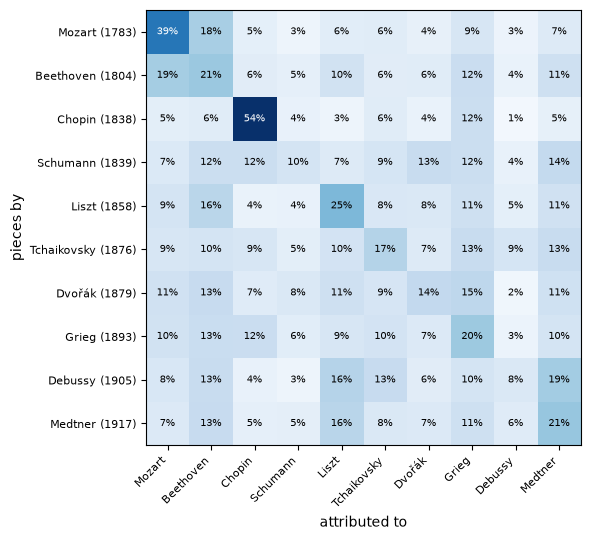

Are composers who lived closer in time mixed up more often? (rank correlation between resemblance and closeness in time)


,score,p-value
codes,,
compact (β = 0.1),0.109,0.258
detailed (β = 0.01),0.083,0.320
untrained,-0.087,0.681
simple features,0.105,0.246
compact + simple features,0.056,0.366


In [3]:
classes = sorted(np.unique(composer[piano]), key=lambda c: np.median(year[composer == c]))
labels = [f"{c} ({int(np.median(year[composer == c]))})" for c in classes]
confusion = piano_pieces["compact (β = 0.1)"].groupby("composer")[classes].mean().loc[classes]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(confusion.to_numpy(), cmap="Blues", vmin=0)
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, f"{confusion.iloc[i, j]:.0%}", ha="center", va="center", fontsize=7,
                color="white" if confusion.iloc[i, j] > 0.3 else "black")
ax.set_xticks(range(len(classes)), classes, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(classes)), labels, fontsize=8)
ax.set_xlabel("attributed to")
ax.set_ylabel("pieces by")
fig.tight_layout()
fig.savefig(OUT / "who_sounds_like_whom.png", dpi=150)
plt.show()

years_apart = np.abs(np.subtract.outer([np.median(year[composer == c]) for c in classes],
                                       [np.median(year[composer == c]) for c in classes]))
rows = []
for name, probabilities in piano_pieces.items():
    c = probabilities.groupby("composer")[classes].mean().loc[classes].to_numpy()
    resemblance = (c + c.T) / 2
    rho, p = mantel(-resemblance, years_apart)
    rows.append({"codes": name, "score": rho, "p-value": p})
print("Are composers who lived closer in time mixed up more often? "
      "(rank correlation between resemblance and closeness in time)")
display(pd.DataFrame(rows).set_index("codes").round(3))

Some composers are much easier to recognise than others. Chopin's pieces are attributed to him 54%
of the time and Mozart's 39%, while Schumann's (10%) and Debussy's (8%) are rarely recognised,
partly because there are only 13 Schumann and 3 Debussy pieces to learn from. Several confusions
make musical sense: Mozart and Beethoven are mistaken for each other (18-19% each way), and
Debussy's pieces go to the other 20th-century composer, Medtner, more often than to anyone else
(19%), followed by Liszt.

Taken as a whole, though, the confusions don't follow history: composers who lived closer in time
are not mixed up more often than others. The correlation is about 0.1 and could easily be chance,
for every kind of code. With ten composers, this test can only detect a strong effect, so the honest
conclusion is that the resemblances the code captures are not simply a timeline.

## 3. When was it written?

For solo piano, a probe now guesses the year each piece was composed, again for pieces it never
saw. We average its guesses over the bars of a piece and measure the typical error in years,
compared with the simplest strategy: always guessing the average year.

Always guessing the average year: typical error of 38 years


,typical error (years),R² (whole pieces),low,high
codes,,,,
compact (β = 0.1),28.68,0.39,0.34,0.45
detailed (β = 0.01),28.59,0.39,0.33,0.45
untrained,32.65,0.23,0.17,0.29
simple features,33.33,0.20,0.14,0.26
compact + simple features,28.28,0.41,0.35,0.46


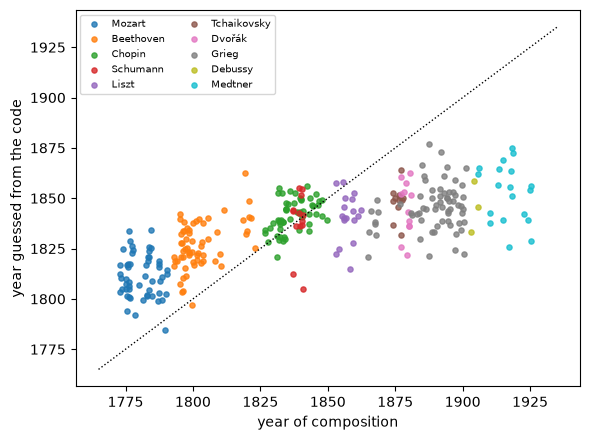

In [4]:
rows, guesses = [], {}
for name, x in representations.items():
    predicted = cross_validated_predictions(x[piano], year[piano], pieces[piano], "number")
    by_piece = pd.DataFrame({"piece": pieces[piano], "composer": composer[piano],
                             "year": year[piano], "guess": predicted}).groupby("piece") \
        .agg(year=("year", "first"), guess=("guess", "mean"), composer=("composer", "first"))
    guesses[name] = by_piece
    score = score_predictions(by_piece.year.to_numpy(), by_piece.guess.to_numpy(),
                              by_piece.index.to_numpy(), "number")
    rows.append({"codes": name, "typical error (years)": (by_piece.guess - by_piece.year).abs().mean(),
                 "R² (whole pieces)": score.score, "low": score.low, "high": score.high})
dating = pd.DataFrame(rows).set_index("codes")
baseline = (guesses["compact (β = 0.1)"].year - guesses["compact (β = 0.1)"].year.mean()).abs().mean()
print(f"Always guessing the average year: typical error of {baseline:.0f} years")
display(dating.round(2))

fig, ax = plt.subplots(figsize=(6, 4.5))
g = guesses["compact (β = 0.1)"]
for c in classes:
    part = g[g.composer == c]
    ax.scatter(part.year + np.random.default_rng(0).uniform(-2, 2, len(part)), part.guess,
               s=14, label=c, alpha=0.8)
lims = [g.year.min() - 10, g.year.max() + 10]
ax.plot(lims, lims, "k:", linewidth=1)
ax.set_xlabel("year of composition")
ax.set_ylabel("year guessed from the code")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(OUT / "dating_pieces.png", dpi=150)

The compact model's code dates a typical unseen piece within 29 years, against 38 years when always
guessing the average year, and about 33 years for the simple features and the untrained model. As
for composers, the detailed model does no better than the compact one.

The plot shows how. The code gets the *order* of the music broadly right: Mozart's pieces are dated
earlier than Chopin's, which are dated earlier than Grieg's and Medtner's. But it squeezes everything
towards the middle of the period, dating Mozart around 1810 and Medtner around 1850. The code
carries a sense of time, but a blurred one: a single bar holds only so much of what makes music
sound of its era.

## 4. What does "later" sound like?

Finally, as in the second notebook, we draw an arrow in the compact model's code: from the
average code of the earliest quarter of solo piano bars to that of the latest quarter. Then we
take bars of Mozart and Beethoven (before 1810) from the validation pieces, push them along that
arrow, and measure what changes. We compare those changes with the real differences between
late piano music (from 1880) and early piano music (before 1810).

In [5]:
model = load_checkpoint("runs/full/best.pt")[0]
z = codes["compact (β = 0.1)"].mean
later = mean_difference_direction(z[piano], year[piano])
spread = spread_along(z[piano], later)
early = np.flatnonzero(piano & (year < 1810) & (bars.split == "valid").to_numpy()
                       & (bars.bar_len == 16).to_numpy())
early = np.random.default_rng(0).choice(early, min(150, len(early)), replace=False)
moved = move_and_measure(model, z[early], later, np.array([0.0, 1.0, 2.0]) * spread, bar_len=16)

columns = {"pitch_mean": "register", "pitch_range": "range from lowest to highest note",
           "chord_size": "notes played together", "duration_mean": "note length",
           "n_notes": "number of notes", "top_line_leap": "melodic leaps",
           "pitch_class_entropy": "variety of note names", "dissonance": "dissonance"}
spread_of = features.loc[piano, list(columns)].std()
means = moved.groupby("amount")[list(columns)].mean()
real = (features.loc[piano & (year >= 1880), list(columns)].mean()
        - features.loc[piano & (year < 1810), list(columns)].mean()) / spread_of
comparison = pd.DataFrame({
    "pushing early bars towards 'later'": (means.iloc[-1] - means.iloc[0]) / spread_of,
    "real difference, late minus early": real}).rename(index=columns)
display(comparison.round(2))
print("(changes in units of the spread of each feature across solo piano bars)")

,pushing early bars towards 'later',"real difference, late minus early"
register,-0.67,-0.27
range from lowest to highest note,0.55,0.25
notes played together,1.09,0.43
note length,0.53,0.37
number of notes,0.14,0.06
melodic leaps,0.24,0.07
variety of note names,0.23,0.11
dissonance,-0.01,0.09


(changes in units of the spread of each feature across solo piano bars)


Pushed towards "later", the early bars change in a recognisable way: they move lower on the keyboard
and spread wider, with bigger chords, longer notes, more leaps in the melody and a greater variety of
note names. That is the fuller, richer piano writing of the later 19th century, and the real
differences between late and early piano music in the corpus go the same way for seven of the eight
measurements, though less strongly. The exception is dissonance, which the direction leaves
untouched, just as the "dissonance" direction of the second notebook barely changed dissonance.

A caveat: "later" here means "more like the late composers of this corpus (mainly Grieg, Debussy and
Medtner) than like Mozart and early Beethoven". It is a direction learned from eleven composers, not
a general law of music history. Listen to a bar of Beethoven pushed step by step towards "later":

Example: Ludwig van Beethoven 05-3 (bar 5), in C


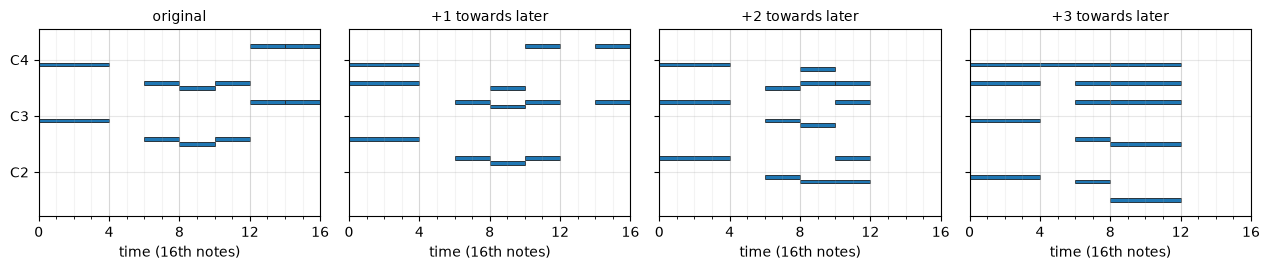

Listen: [towards_later.wav](outputs/q4/towards_later.wav)

In [6]:
candidates = [i for i in early if 8 <= features.n_notes[i] <= 14
              and decode(model, z[i])[0] == dataset.notes(i)]
example = (candidates or list(early))[0]  # a bar the model plays back perfectly, if any
print("Example:", bars.composer[example], bars.piece[example], f"(bar {bars.mn[example]}), in C")
steps = np.array([0.0, 1.0, 2.0, 3.0])
path = decode(model, z[example] + steps[:, None] * spread * later)
titles = ["original"] + [f"+{s:g} towards later" for s in steps[1:]]
fig = plot_bars(path, titles, [16] * 4)
fig.savefig(OUT / "towards_later.png", dpi=150)
plt.show()
save_wav(synthesize(path, [16] * 4, gap_steps=4), OUT / "towards_later.wav")
to_midi(path, OUT / "towards_later.mid", [16] * 4, gap_steps=4)
listen(OUT / "towards_later.wav")

## Summary

- **The code knows something about composers.** Out of eleven composers, it recognises the right one
  from a single bar a third of the time, and from a whole piece half the time. Much of this is
  already visible in simple surface statistics: the model's code adds a real but modest edge,
  mostly for whole pieces.
- **Some composers are distinctive, others blend in.** Chopin stands out; Schumann and Debussy
  hardly do. The mix-ups often make musical sense (Mozart and Beethoven), but they don't follow a
  timeline.
- **The code has a blurred sense of time.** It dates piano pieces within about 29 years and gets
  their order roughly right, but squeezes everything towards the middle of the period.
- **"Later" has a sound.** Pushing early bars towards later music makes them lower, wider and fuller,
  much like real late-19th-century piano writing, though not more dissonant.
- **Remembering more doesn't help here.** The detailed model, which plays bars back better, is no
  better at recognising composers or dating pieces than the compact one.

All of this comes from a model that never saw more than one bar at a time and was never told who
wrote anything. Style unfolds over phrases and movements, so a model reading longer stretches of
music would likely see much more: that would be the natural next step.